# Seller Performance Analysis

**Business question (Management):** How are sales distributed among sellers, and do the top-selling sellers also perform well in customer satisfaction?

**Scope:**
- A1: Seller distribution by state
- A2: Top sellers by sales
- A3: Sales concentration
- A4: Rank by items sold vs. rank by sales
- A5: Seller review scores and sales
- A6: High-sales sellers with below-average scores

**Data:** `sellers`, `order_items` and `order_reviews`. Cleaned tables are used when available, otherwise the raw tables.

**Definitions**
- **Items sold:** number of `order_items` rows of the seller. **Product sales:** `SUM(price)` (freight excluded, not profit).
- **Unique orders:** `nunique(order_id)` of the seller's items.
- **Active seller:** a seller with at least one item in `order_items`.
- **Review attribution:** reviews belong to orders, not to sellers. An order's score is the mean of its review scores, and it is assigned to every seller who has items in that order. A shared review cannot show which seller caused the rating.
- **Minimum sample:** averages are only compared for sellers with enough reviews (the limit is chosen in A5).

In [1]:
# Libraries and display settings
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)   # show numbers with 2 decimals

# Tables used in this analysis
order_items = pd.read_parquet("../Data/Processed/order_items_clean.parquet")
sellers = pd.read_parquet("../Data/Processed/sellers_clean.parquet")

## Part A: Seller Performance Analysis

### A1. Seller Distribution

In [2]:
# Check: the sellers table should have one row per seller (no duplicated seller_id)
print("Unique sellers:", sellers["seller_id"].nunique())
print("Rows in sellers table:", len(sellers))
print("Duplicated seller_id:", sellers["seller_id"].duplicated().sum())

Unique sellers: 3095
Rows in sellers table: 3095
Duplicated seller_id: 0


In [3]:
# Active sellers = sellers that appear in order_items
print("Unique sellers in order_items:", order_items["seller_id"].nunique())
print("Active sellers (in the sellers table and in order_items):", sellers["seller_id"].isin(order_items["seller_id"]).sum())

# Number of sellers per state and share of sellers (%)
state_counts = sellers["seller_state"].value_counts()
state_share = (state_counts / state_counts.sum() * 100).round(2)
print("Number of states:", len(state_counts))
print("Check (should be 3095):", state_counts.sum())

# Top 10 states
top_states = state_counts.head(10)
print("\nTop 10 states: number of sellers")
display(top_states)
print("Top 10 states: share of sellers (%)")
display(state_share.head(10))

Unique sellers in order_items: 3095
Active sellers (in the sellers table and in order_items): 3095
Number of states: 23
Check (should be 3095): 3095

Top 10 states: number of sellers


seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
Name: count, dtype: int64

Top 10 states: share of sellers (%)


seller_state
SP   59.74
PR   11.28
MG    7.88
SC    6.14
RJ    5.53
RS    4.17
GO    1.29
DF    0.97
ES    0.74
BA    0.61
Name: count, dtype: float64

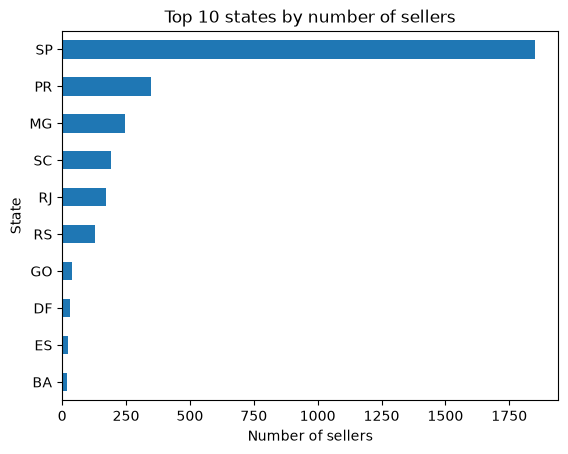

In [4]:
# Chart: top 10 states by number of sellers
top_states.sort_values().plot(kind="barh", title="Top 10 states by number of sellers")
plt.xlabel("Number of sellers")
plt.ylabel("State")
plt.show()

**Report A1:** There are 3,095 unique sellers (one row per seller, no duplicates), and all of them are active, meaning each has at least one item in `order_items`. The sellers are located in 23 states. Seller locations are very concentrated: São Paulo (SP) has 1,849 sellers (59.74%), followed by PR (349; 11.28%), MG (244; 7.88%), SC (190; 6.14%), RJ (171; 5.53%) and RS (129; 4.17%). The top 10 states contain 98.35% of all sellers, and the other 13 states have only 51 sellers together. These counts show where sellers are registered, not where their sales are made.

### A2. Seller Sales Performance

Seller sales add up to the item-level total: True
Number of sellers matches order_items: True

Top 10 sellers by product sales:


,items_sold,sales,orders
seller_id,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1156,"229,472.63",1132
53243585a1d6dc2643021fd1853d8905,410,"222,776.05",358
4a3ca9315b744ce9f8e9374361493884,1987,"200,472.92",1806
fa1c13f2614d7b5c4749cbc52fecda94,586,"194,042.03",585
7c67e1448b00f6e969d365cea6b010ab,1364,"187,923.89",982
7e93a43ef30c4f03f38b393420bc753a,340,"176,431.87",336
da8622b14eb17ae2831f4ac5b9dab84a,1551,"160,236.57",1314
7a67c85e85bb2ce8582c35f2203ad736,1171,"141,745.53",1160
1025f0e2d44d7041d6cf58b6550e0bfa,1428,"138,968.55",915


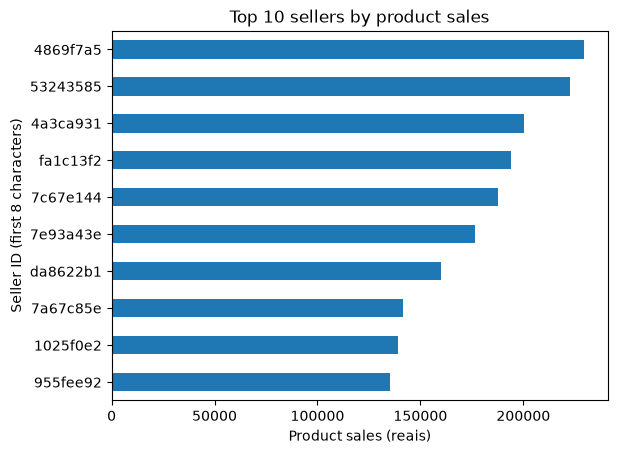

In [5]:
# Items sold, product sales and unique orders for each seller
seller_stats = order_items.groupby("seller_id").agg(items_sold = ("price", "size"), sales = ("price", "sum"), orders = ("order_id", "nunique"))

# Checks: the totals must match the item-level table
print("Seller sales add up to the item-level total:", seller_stats["sales"].sum() == order_items["price"].sum())
print("Number of sellers matches order_items:", order_items["seller_id"].nunique() == len(seller_stats))

# Top 10 sellers by product sales
top10 = seller_stats.nlargest(10, "sales")
print("\nTop 10 sellers by product sales:")
display(top10)

# Chart: top 10 sellers by product sales (seller_id shortened to 8 characters)
plot_data = top10["sales"].copy()
plot_data.index = plot_data.index.str[:8]
plot_data.sort_values().plot(kind="barh", title="Top 10 sellers by product sales")
plt.xlabel("Product sales (reais)")
plt.ylabel("Seller ID (first 8 characters)")
plt.show()

**Report A2:** Items sold, product sales and unique orders were calculated for each of the 3,095 sellers (checks passed: the seller sales add up to the item-level total). The top seller (4869f7a5) has R\\$229,473 in sales from 1,156 items and 1,132 orders, closely followed by 53243585 (R\\$222,776; 410 items; 358 orders). The ten best sellers have sales between R\\$135,172 and R\\$229,473 and sold between 340 and 1,987 items, so sellers with similar sales can differ a lot in volume. For example, 53243585 earns almost the same as the top seller from only 410 items (about R\$543 per item), while 4a3ca931 sells 1,987 items at about R\\$101 each.

### A3. Seller Revenue Concentration

Cumulative share after the last seller (should be 100): 100.0

Seller sales concentration summary:


,Metric,Value
0,Top 10 sellers: share of sales (%),13.15
1,Top 50 sellers: share of sales (%),32.89
2,Top 100 sellers: share of sales (%),45.06
3,Sellers needed for 50% of sales,130.00
4,Sellers needed for 80% of sales,544.00
5,Mean sales per seller,"4,391.48"
6,Median sales per seller,821.48


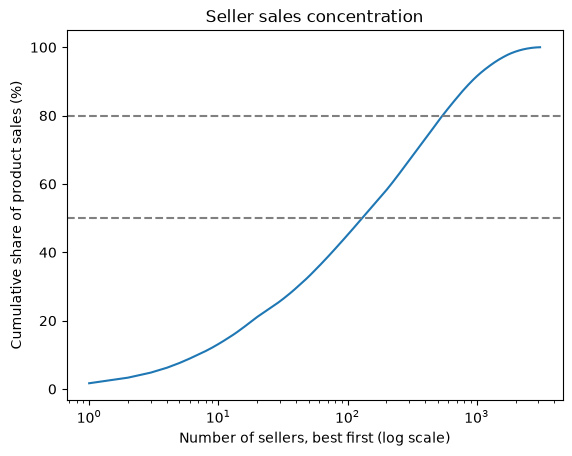

In [6]:
# Total sales and the top 50 / top 100 sellers
total_sales = seller_stats["sales"].sum()
top50 = seller_stats.nlargest(50, "sales")
top100 = seller_stats.nlargest(100, "sales")

# Cumulative share of sales (sellers sorted from the biggest to the smallest)
sorted_sales = seller_stats["sales"].sort_values(ascending = False)
cum_share = sorted_sales.cumsum() / total_sales * 100
print("Cumulative share after the last seller (should be 100):", round(cum_share.iloc[-1], 2))

# Summary table of the concentration
summary = pd.DataFrame({
    "Metric": ["Top 10 sellers: share of sales (%)",
               "Top 50 sellers: share of sales (%)",
               "Top 100 sellers: share of sales (%)",
               "Sellers needed for 50% of sales",
               "Sellers needed for 80% of sales",
               "Mean sales per seller",
               "Median sales per seller"],
    "Value": [round(top10["sales"].sum() / total_sales * 100, 2),
              round(top50["sales"].sum() / total_sales * 100, 2),
              round(top100["sales"].sum() / total_sales * 100, 2),
              (cum_share < 50).sum() + 1,
              (cum_share < 80).sum() + 1,
              round(seller_stats["sales"].mean(), 2),
              round(seller_stats["sales"].median(), 2)]
})
print("\nSeller sales concentration summary:")
display(summary)

# Chart: cumulative share of sales (log scale on the x axis)
plt.plot(range(1, len(cum_share) + 1), cum_share.values)
plt.xscale("log")
plt.axhline(50, color="gray", linestyle="--")
plt.axhline(80, color="gray", linestyle="--")
plt.xlabel("Number of sellers, best first (log scale)")
plt.ylabel("Cumulative share of product sales (%)")
plt.title("Seller sales concentration")
plt.show()

**Report A3:** The ten largest sellers account for 13.15% of total product sales, and no single seller has more than 1.7%, so sales do not depend on a handful of sellers. However, sales are concentrated in a small group: the top 50 sellers make 32.89% and the top 100 (3.2% of sellers) make 45.06%. About 130 sellers (4.2%) are needed to reach half of all sales and 544 sellers (17.6%) to reach 80%. The mean sales per seller (4,391 reais) is about five times the median (821 reais), so a few large sellers pull the average up while the typical seller sells much less. The cumulative curve rises quickly for the first hundred sellers and flattens afterwards.

### A4. Rank by Items Sold vs. Rank by Sales

In [7]:
# Ranks: 1 = highest. rank_gap > 0 means the seller ranks lower in sales than in items sold
seller_stats["rank_items"] = seller_stats["items_sold"].rank(ascending = False, method = 'min').astype(int)
seller_stats["rank_sales"] = seller_stats["sales"].rank(ascending = False, method = 'min').astype(int)
seller_stats["rank_gap"] = seller_stats["rank_sales"] - seller_stats["rank_items"]
seller_stats["avg_price"] = seller_stats["sales"] / seller_stats["items_sold"]      # average price per item

# Top 10 sellers by items sold, and how many are also in the top 10 by sales
top10_items = seller_stats.nlargest(10, "items_sold")
print("Top 10 sellers by items sold:")
display(top10_items[["items_sold", "rank_items", "sales", "rank_sales", "avg_price"]])
print("Sellers in both top 10 lists:", len(set(top10_items.index) & set(top10.index)))

# Important differences between the two rankings
cols = ["items_sold", "rank_items", "sales", "rank_sales", "avg_price", "orders"]
print("\nHigh items rank, much lower sales rank:")
display(seller_stats[(seller_stats["rank_gap"] >= 10) & (seller_stats["rank_items"] <= 20)][cols])
print("Much higher sales rank than items rank:")
display(seller_stats[(seller_stats["rank_gap"] <= -10) & (seller_stats["rank_sales"] <= 20)][cols])

Top 10 sellers by items sold:


,items_sold,rank_items,sales,rank_sales,avg_price
seller_id,,,,,
6560211a19b47992c3666cc44a7e94c0,2033,1,"123,304.83",12,60.65
4a3ca9315b744ce9f8e9374361493884,1987,2,"200,472.92",3,100.89
1f50f920176fa81dab994f9023523100,1931,3,"106,939.21",16,55.38
cc419e0650a3c5ba77189a1882b7556a,1775,4,"104,288.42",17,58.75
da8622b14eb17ae2831f4ac5b9dab84a,1551,5,"160,236.57",7,103.31
955fee9216a65b617aa5c0531780ce60,1499,6,"135,171.70",10,90.17
1025f0e2d44d7041d6cf58b6550e0bfa,1428,7,"138,968.55",9,97.32
7c67e1448b00f6e969d365cea6b010ab,1364,8,"187,923.89",5,137.77
ea8482cd71df3c1969d7b9473ff13abc,1203,9,"37,177.52",62,30.90


Sellers in both top 10 lists: 6

High items rank, much lower sales rank:


,items_sold,rank_items,sales,rank_sales,avg_price,orders
seller_id,,,,,,
1f50f920176fa81dab994f9023523100,1931,3,"106,939.21",16,55.38,1404
391fc6631aebcf3004804e51b40bcf1e,613,20,"39,951.95",57,65.17,526
6560211a19b47992c3666cc44a7e94c0,2033,1,"123,304.83",12,60.65,1854
8b321bb669392f5163d04c59e235e066,1018,13,"17,535.69",142,17.23,943
cc419e0650a3c5ba77189a1882b7556a,1775,4,"104,288.42",17,58.75,1706
cca3071e3e9bb7d12640c9fbe2301306,830,14,"64,009.89",25,77.12,712
d2374cbcbb3ca4ab1086534108cc3ab7,631,19,"21,223.92",124,33.64,524
e9779976487b77c6d4ac45f75ec7afe9,750,17,"43,162.95",51,57.55,657
ea8482cd71df3c1969d7b9473ff13abc,1203,9,"37,177.52",62,30.90,1146


Much higher sales rank than items rank:


,items_sold,rank_items,sales,rank_sales,avg_price,orders
seller_id,,,,,,
46dc3b2cc0980fb8ec44634e21d2718e,542,25,"128,111.19",11,236.37,521
4869f7a5dfa277a7dca6462dcf3b52b2,1156,11,"229,472.63",1,198.51,1132
53243585a1d6dc2643021fd1853d8905,410,38,"222,776.05",2,543.36,358
5dceca129747e92ff8ef7a997dc4f8ca,346,48,"112,155.53",15,324.15,325
7e93a43ef30c4f03f38b393420bc753a,340,51,"176,431.87",6,518.92,336
edb1ef5e36e0c8cd84eb3c9b003e486d,175,126,"79,284.55",20,453.05,166
fa1c13f2614d7b5c4749cbc52fecda94,586,21,"194,042.03",4,331.13,585


**Report A4:** The rankings of sellers by items sold and by product sales are similar but not identical: the rank correlation is 0.85, and only 6 of the top 10 sellers by items are also in the top 10 by sales. The difference comes from the average price per item. Some high-volume sellers rank much lower in sales because they sell cheap items: 8b321bb6 is 13th by items (1,018) but 142nd by sales (average price 17.23 reais), ea8482cd is 9th by items (1,203) but 62nd by sales (30.90 reais), and d2374cbc is 19th by items but 124th by sales (33.64 reais). The opposite also happens: 53243585 is 38th by items but 2nd by sales (543.36 reais per item), 7e93a43e is 51st by items but 6th by sales (518.92 reais), and edb1ef5e, with only 175 items, is 20th by sales (453.05 reais). Ranking sellers only by items sold would therefore hide some of the highest-value sellers.

### A5. Average Seller Rating

In [8]:
# Reviews table: one row per review (an order can have more than one review)
reviews = pd.read_csv("../Data/Raw/olist_order_reviews_dataset.csv")
print("Orders with a review:", reviews["order_id"].nunique())
print("Number of reviews:", reviews.shape[0])
print("Missing review scores:", reviews["review_score"].isna().sum())
print("\nNumber of reviews for each score:")
display(reviews["review_score"].value_counts().sort_index())

# Score of each order = mean of its review scores, and the overall average score
order_score = reviews.groupby("order_id")["review_score"].mean()
overall_avg = order_score.mean()
print("Overall average score:", round(overall_avg, 2))

# Seller-order pairs: an order counts once for each seller who has items in it
seller_orders = order_items[["seller_id", "order_id"]].drop_duplicates()
print("Pairs match the sellers' order counts:", len(seller_orders) == seller_stats["orders"].sum())

# Add the order score to each pair (.map keeps the number of rows)
seller_orders["score"] = seller_orders["order_id"].map(order_score)
print("Seller-order pairs after adding scores:", len(seller_orders))
print("Pairs without a review:", seller_orders["score"].isna().sum())

# Average score and number of reviewed orders for each seller, joined to seller_stats
review_stats = seller_orders.groupby("seller_id").agg(avg_score = ("score", "mean"), reviewed_orders = ("score", "count"))
seller_full = seller_stats.join(review_stats)
print("Number of sellers after the join:", len(seller_full))

Orders with a review: 98673
Number of reviews: 99224
Missing review scores: 0

Number of reviews for each score:


review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Overall average score: 4.09
Pairs match the sellers' order counts: True
Seller-order pairs after adding scores: 100010
Pairs without a review: 763
Number of sellers after the join: 3095


In [9]:
# Minimum sample: only sellers with at least 30 reviewed orders
enough = seller_full[seller_full["reviewed_orders"] >= 30]
print("Sellers with at least 30 reviewed orders:", len(enough))
print("Share of total sales covered by these sellers (%):", round(enough["sales"].sum() / total_sales * 100, 2))


Sellers with at least 30 reviewed orders: 628
Share of total sales covered by these sellers (%): 76.58


Top 20 sellers below the overall average score: 7


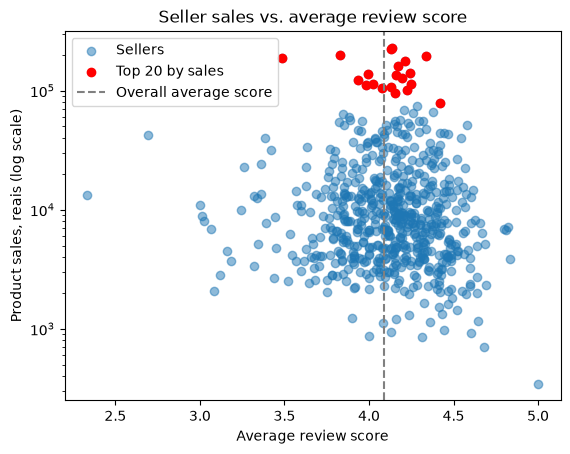

In [10]:
# Chart: sales vs. average score (the top 20 sellers by sales are in red)
top20 = enough.nlargest(20, "sales")
print("Top 20 sellers below the overall average score:", (top20["avg_score"] < overall_avg).sum())

plt.scatter(enough["avg_score"], enough["sales"], alpha=0.5, label="Sellers")
plt.scatter(top20["avg_score"], top20["sales"], color="red", label="Top 20 by sales")
plt.axvline(overall_avg, color="gray", linestyle="--", label="Overall average score")
plt.yscale("log")
plt.xlabel("Average review score")
plt.ylabel("Product sales, reais (log scale)")
plt.title("Seller sales vs. average review score")
plt.legend()
plt.show()

**Report A5:** Reviews belong to orders, so the score of each order (the mean of its reviews) was assigned to every seller who has items in that order, counting each seller-order pair once (100,010 pairs; the row count was checked after the join). The 99,224 review rows cover 98,673 orders, the overall average score is 4.09, and 763 seller-order pairs have no review. To avoid unstable averages, only sellers with at least 30 reviewed orders were used: 628 of the 3,095 sellers, who make 76.58% of product sales. Among them, sales and average score are almost unrelated (rank correlation -0.08), so selling more does not mean better or worse scores. In the scatter plot, 7 of the 20 top-selling sellers are below the overall average score. Because the review is shared by the whole order, it cannot show which seller caused a rating when an order contains items from several sellers.

### A6. High-Sales Sellers with Below-Average Scores

In [11]:
# High-sales sellers = sellers with enough reviews whose sales are in the top 10%
sales_limit = enough["sales"].quantile(0.9)
high_sales = enough[enough["sales"] >= sales_limit]

# Candidates = high-sales sellers whose average score is below the overall average
candidates = high_sales[high_sales["avg_score"] < overall_avg].copy()
candidates["score_gap"] = candidates["avg_score"] - overall_avg      # negative = below the overall average

print("Sales limit (top 10% of the sellers with enough reviews):", round(sales_limit, 2))
print("High-sales sellers:", len(high_sales))
print("High-sales sellers below the overall average score:", len(candidates))
print("Of these, at least 0.2 points below the average:", (candidates["score_gap"] <= -0.2).sum())

cols = ["items_sold", "sales", "orders", "reviewed_orders", "avg_score", "score_gap", "avg_price"]
print("\nAll candidates (sorted by sales):")
display(candidates.sort_values("sales", ascending=False)[cols])

Sales limit (top 10% of the sellers with enough reviews): 37095.3
High-sales sellers: 63
High-sales sellers below the overall average score: 23
Of these, at least 0.2 points below the average: 8

All candidates (sorted by sales):


,items_sold,sales,orders,reviewed_orders,avg_score,score_gap,avg_price
seller_id,,,,,,,
4a3ca9315b744ce9f8e9374361493884,1987,"200,472.92",1806,1785,3.83,-0.26,100.89
7c67e1448b00f6e969d365cea6b010ab,1364,"187,923.89",982,976,3.49,-0.60,137.77
1025f0e2d44d7041d6cf58b6550e0bfa,1428,"138,968.55",915,907,3.99,-0.09,97.32
6560211a19b47992c3666cc44a7e94c0,2033,"123,304.83",1854,1838,3.94,-0.15,60.65
7d13fca15225358621be4086e1eb0964,578,"113,628.97",565,561,4.02,-0.06,196.59
5dceca129747e92ff8ef7a997dc4f8ca,346,"112,155.53",325,321,3.98,-0.10,324.15
cc419e0650a3c5ba77189a1882b7556a,1775,"104,288.42",1706,1698,4.07,-0.01,58.75
cca3071e3e9bb7d12640c9fbe2301306,830,"64,009.89",712,700,3.85,-0.24,77.12
04308b1ee57b6625f47df1d56f00eedf,94,"60,130.60",94,94,3.88,-0.20,639.69


In [12]:
# Selected for further investigation: at least 0.2 points below the average AND at least 100 reviewed orders
selected = candidates[(candidates["score_gap"] <= -0.2) & (candidates["reviewed_orders"] >= 100)]
print("Selected sellers:", len(selected))
display(selected.sort_values("sales", ascending=False)[cols])
print("Share of total sales of the selected sellers (%):", round(selected["sales"].sum() / total_sales * 100, 2))

# Same gap but fewer than 100 reviewed orders: the sample is too small to conclude (watch list)
small_sample = candidates[(candidates["score_gap"] <= -0.2) & (candidates["reviewed_orders"] < 100)]
print("\nWatch list (low score but fewer than 100 reviewed orders):")
display(small_sample[cols])

Selected sellers: 5


,items_sold,sales,orders,reviewed_orders,avg_score,score_gap,avg_price
seller_id,,,,,,,
4a3ca9315b744ce9f8e9374361493884,1987,"200,472.92",1806,1785,3.83,-0.26,100.89
7c67e1448b00f6e969d365cea6b010ab,1364,"187,923.89",982,976,3.49,-0.60,137.77
cca3071e3e9bb7d12640c9fbe2301306,830,"64,009.89",712,700,3.85,-0.24,77.12
25c5c91f63607446a97b143d2d535d31,269,"54,679.22",158,157,3.82,-0.27,203.27
2eb70248d66e0e3ef83659f71b244378,212,"42,628.61",202,198,2.69,-1.39,201.08


Share of total sales of the selected sellers (%): 4.04

Watch list (low score but fewer than 100 reviewed orders):


,items_sold,sales,orders,reviewed_orders,avg_score,score_gap,avg_price
seller_id,,,,,,,
04308b1ee57b6625f47df1d56f00eedf,94,"60,130.60",94,94,3.88,-0.20,639.69
712e6ed8aa4aa1fa65dab41fed5737e4,87,"39,815.00",79,78,3.38,-0.70,457.64
966cb4760537b1404caedd472cc610a5,75,"51,286.05",75,74,3.85,-0.24,683.81


**Report A6:** Among the 628 sellers with at least 30 reviewed orders, the high-sales group (sales of at least 37,095 reais, the top 10%) has 63 sellers, and 23 of them have an average score below the overall average of 4.09. For 15 of these 23 the gap is smaller than 0.2 points, so only 8 are clearly lower. Five of these 8 have at least 100 reviewed orders and were selected for further investigation: 2eb70248 (score 2.69 from 198 reviewed orders; sales 42,629 reais), 7c67e144 (3.49; 976 reviewed orders; 187,924 reais, 5th in sales), 4a3ca931 (3.83; 1,785; 200,473 reais, 3rd in sales), cca3071e (3.85; 700; 64,010 reais) and 25c5c91f (3.82; 157; 54,679 reais). Together they make 4.04% of product sales. Three other sellers (04308b1e, 712e6ed8, 966cb476) also have low scores, but only 74 to 94 reviewed orders, so they were not selected and should only be monitored. Because a review is shared by the whole order, a low score cannot be linked to one seller with certainty, especially when an order has items from several sellers.

### Part A: Final Report and Business Conclusion

**Data and method.** `sellers` (3,095 rows), `order_items` (112,650 items) and `order_reviews` (99,224 reviews) were used. Product sales are `SUM(price)` and are not profit. The score of an order (mean of its reviews) was assigned to every seller who has items in that order. The joins were checked (3,095 sellers, 100,010 seller-order pairs, totals matched).

**Main results**
- **Distribution (A1):** 3,095 sellers, all active, in 23 states. SP has 59.74% of the sellers and the top 10 states have 98.35%.
- **Top sellers (A2):** the best seller has 229,473 reais in sales; the top 10 sellers sell between 135,172 and 229,473 reais.
- **Concentration (A3):** the top 10 sellers make 13.15% of sales; 130 sellers (4.2%) make half of the sales and 544 sellers (17.6%) make 80%.
- **Rankings (A4):** the rankings by items and by sales are similar (rank correlation 0.85) but differ because of the price per item.
- **Satisfaction (A5, A6):** the overall average score is 4.09, and sales and score are almost unrelated (-0.08). Five high-sales sellers were selected for review.

**Business conclusion**
- **Does Olist depend on a few sellers?** Not on a handful: the biggest seller has less than 1.7% of sales and the top 10 only 13.15%. But sales are concentrated in a minority: about 4% of the sellers make half of the sales, and the top 100 make 45%.
- **Which sellers need further review?** The five sellers selected in A6. 2eb70248 has the lowest score (2.69), and 7c67e144 (3.49) and 4a3ca931 (3.83) combine large sales with below-average scores. Three sellers with low scores but few reviews should only be monitored.
- Selling more does not mean worse satisfaction: large sellers are not systematically rated lower.

**Limitations.** Product sales are not profit. A review belongs to the whole order, so it cannot show which seller caused it. Averages of sellers with few reviews are unstable (minimum 30 reviewed orders). The analysis does not show changes over time.